<a href="https://colab.research.google.com/github/kaka-ubial/toxic-plants/blob/main/TDE2_Plantas_Toxicas_Pets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🌿 Sistema de Classificação e Identificação de Toxicidade de Plantas para Pets

**TDE 2 — Sistemas de Informação Inteligentes** · PUCPR
Prof.ª Dr.ª Ana Beatriz Dias Pinto · Prof. Dr. Joelton Deonei Gotz

**Equipe:** Izabelly - Karen

---

O usuário tira uma **foto de uma planta** no celular. Uma **rede neural convolucional (CNN)** identifica a espécie, o sistema consulta uma **base de conhecimento de toxicidade (ASPCA)** e um **LLM** transforma o dado bruto em uma explicação clara, com orientação do que fazer, inclusive em caso de emergência, quando o gato ou cachorro já comeu a planta.

### Como este notebook cobre a rubrica

| Requisito do TDE2 | Peso | Onde está no notebook |
|---|---|---|
| **1. Machine Learning** (classificação / Deep Learning / Visão Computacional) | 10% | Seções 2 e 3: CNN EfficientNet-B0 com *transfer learning*, 47 espécies, métricas, matriz de confusão e calibração |
| **2. Integração com LLM** | 10% | Seção 5: normalização de nomes, explicação da toxicidade, orientação de emergência, decisão em baixa confiança e conversa com o usuário |
| **3. Sistema completo Entrada → Processamento → Saída** | 25% | Seções 4, 6 e 7: foto → CNN → normalização → *lookup* na base → LLM → resposta. Banco SQLite de consultas e interface web (Gradio) |
| **4. Ética e responsabilidade** | 5% | Seção 8: confiança, responsabilidade, viés do dataset, privacidade e limites, **com demonstrações em código** |

### Arquitetura

```
 ENTRADA                PROCESSAMENTO                                                SAÍDA
┌──────────┐   ┌──────────────┐   ┌──────────────┐   ┌─────────────┐   ┌──────────┐   ┌───────────────────────┐
│ Foto do  │──▶│ CNN          │──▶│ Normalização │──▶│ Lookup base │──▶│ LLM      │──▶│ Espécie + tóxica?     │
│ celular  │   │ (top-3 +     │   │ do nome      │   │ toxicidade  │   │ (explica │   │ + explicação          │
│ (+ nome) │   │  confiança)  │   │ (regra+LLM)  │   │ (ASPCA)     │   │  /orienta)│  │ + o que fazer         │
└──────────┘   └──────┬───────┘   └──────────────┘   └─────────────┘   └──────────┘   └───────────────────────┘
                      │ baixa confiança → política de decisão (nova foto / resultado parcial)
                      └────────────────────────────▶  registro anônimo no SQLite (sem a foto)
```

> ⚙️ **Antes de começar:** `Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4`. Depois, `Ambiente de execução → Executar tudo`.

## 1. Configuração do ambiente

In [1]:
!pip -q install kagglehub google-genai gradio

import os, re, io, json, time, random, shutil, sqlite3, hashlib, unicodedata, difflib, datetime
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Markdown

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| Dispositivo:", DEVICE)
if DEVICE == "cpu":
    print("⚠️  Sem GPU! Vá em 'Ambiente de execução → Alterar o tipo de ambiente de execução → GPU T4'. Em CPU o treino demora muito.")

PyTorch: 2.11.0+cu130 | Dispositivo: cuda


In [2]:
CONFIG = dict(
    SEED=42,
    IMG_SIZE=224,
    BATCH=64,
    EPOCAS_CABECA=2,          # fase 1: treina só a camada final (backbone congelado)
    EPOCAS_FINE_TUNING=4,     # fase 2: ajusta a rede inteira
    LR_CABECA=1e-3,
    LR_FINE_TUNING=1e-4,
    LIMIAR_CONFIANCA=0.60,    # abaixo disso o resultado não é tratado como "certo"
    LIMIAR_MARGEM=0.20,       # diferença mínima entre 1º e 2º colocado
    LIMIAR_MINIMO=0.30,       # abaixo disso o sistema pede outra foto
    SALVAR_NO_DRIVE=True,     # guarda modelo e dados no Google Drive para não treinar de novo
    PULAR_TREINO_SE_EXISTIR=True,
)

random.seed(CONFIG["SEED"]); np.random.seed(CONFIG["SEED"]); torch.manual_seed(CONFIG["SEED"])

if CONFIG["SALVAR_NO_DRIVE"]:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        PASTA = "/content/drive/MyDrive/TDE2_plantas"
    except Exception as e:
        print("Drive não montado (", e, "). Usando pasta local.")
        PASTA = "/content/TDE2_plantas"
else:
    PASTA = "/content/TDE2_plantas"
os.makedirs(PASTA, exist_ok=True)

CKPT = os.path.join(PASTA, "modelo_plantas.pt")
ZIP_DADOS = os.path.join(PASTA, "dados_256.zip")
DB_PATH = os.path.join(PASTA, "consultas.db")
DADOS = "/content/dados_256"
print("Artefatos em:", PASTA)

Mounted at /content/drive
Artefatos em: /content/drive/MyDrive/TDE2_plantas


## 2. Dados — *House Plant Species* (Kaggle)

Dataset público com **14.790 imagens de 47 espécies de plantas de interior**, coletadas do Bing Images e curadas manualmente (por não especialistas). Ele foi criado justamente para um projeto de toxicidade de plantas para gatos.

**Pré-processamento:**
1. Abre cada imagem, corrige a rotação EXIF e converte para RGB (descarta arquivos corrompidos).
2. Remove **duplicatas exatas** por hash MD5, para evitar que a mesma foto caia no treino e no teste (vazamento de dados).
3. Redimensiona o lado menor para 256 px, o que deixa o dataset ~25× menor e o treino muito mais rápido.

Na primeira execução o download (~5 GB) e o processamento levam alguns minutos. O resultado fica salvo no Drive para as próximas vezes.

In [3]:
def achar_raiz_classes(caminho, minimo=40):
    for raiz, dirs, _ in os.walk(caminho):
        if len(dirs) >= minimo:
            return raiz
    raise RuntimeError("Não encontrei a pasta com as classes dentro de " + caminho)

def preprocessar(origem, destino, lado=256):
    from concurrent.futures import ThreadPoolExecutor
    tarefas, vistos, dup = [], set(), 0
    for classe in sorted(os.listdir(origem)):
        d_in = os.path.join(origem, classe)
        if not os.path.isdir(d_in):
            continue
        os.makedirs(os.path.join(destino, classe), exist_ok=True)
        for i, f in enumerate(sorted(os.listdir(d_in))):
            p = os.path.join(d_in, f)
            with open(p, "rb") as fh:
                h = hashlib.md5(fh.read()).hexdigest()
            if h in vistos:
                dup += 1
                continue
            vistos.add(h)
            tarefas.append((p, os.path.join(destino, classe, f"{i:05d}.jpg")))

    def proc(t):
        src, dst = t
        try:
            with Image.open(src) as im:
                im = ImageOps.exif_transpose(im).convert("RGB")
                w, h = im.size
                s = lado / min(w, h)
                if s < 1:
                    im = im.resize((round(w * s), round(h * s)), Image.BICUBIC)
                im.save(dst, "JPEG", quality=90)
            return True
        except Exception:
            return False

    with ThreadPoolExecutor(8) as ex:
        ok = list(ex.map(proc, tarefas))
    print(f"Imagens válidas: {sum(ok)} | corrompidas/ilegíveis: {len(ok) - sum(ok)} | duplicadas removidas: {dup}")

if os.path.isdir(DADOS) and len(os.listdir(DADOS)) >= 40:
    print("Dados já preparados nesta sessão.")
elif os.path.exists(ZIP_DADOS):
    print("Restaurando dados pré-processados do Drive...")
    shutil.unpack_archive(ZIP_DADOS, DADOS)
else:
    import kagglehub
    print("Baixando dataset do Kaggle (~5 GB)...")
    bruto = kagglehub.dataset_download("kacpergregorowicz/house-plant-species")
    raiz = achar_raiz_classes(bruto)
    t0 = time.time()
    preprocessar(raiz, DADOS)
    print(f"Pré-processamento em {time.time() - t0:.0f}s. Salvando cópia no Drive...")
    shutil.make_archive(ZIP_DADOS[:-4], "zip", DADOS)

CLASSES = sorted(d for d in os.listdir(DADOS) if os.path.isdir(os.path.join(DADOS, d)))
print(len(CLASSES), "classes")

Baixando dataset do Kaggle (~5 GB)...


100%|██████████| 4.85G/4.85G [01:04<00:00, 81.1MB/s]

Extracting files...



/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Imagens válidas: 14790 | corrompidas/ilegíveis: 0 | duplicadas removidas: 0
Pré-processamento em 645s. Salvando cópia no Drive...
47 classes


> 💡 Se o download der erro de autenticação, rode `import kagglehub; kagglehub.login()` e cole seu usuário e token do Kaggle (em kaggle.com → *Settings* → *API*).

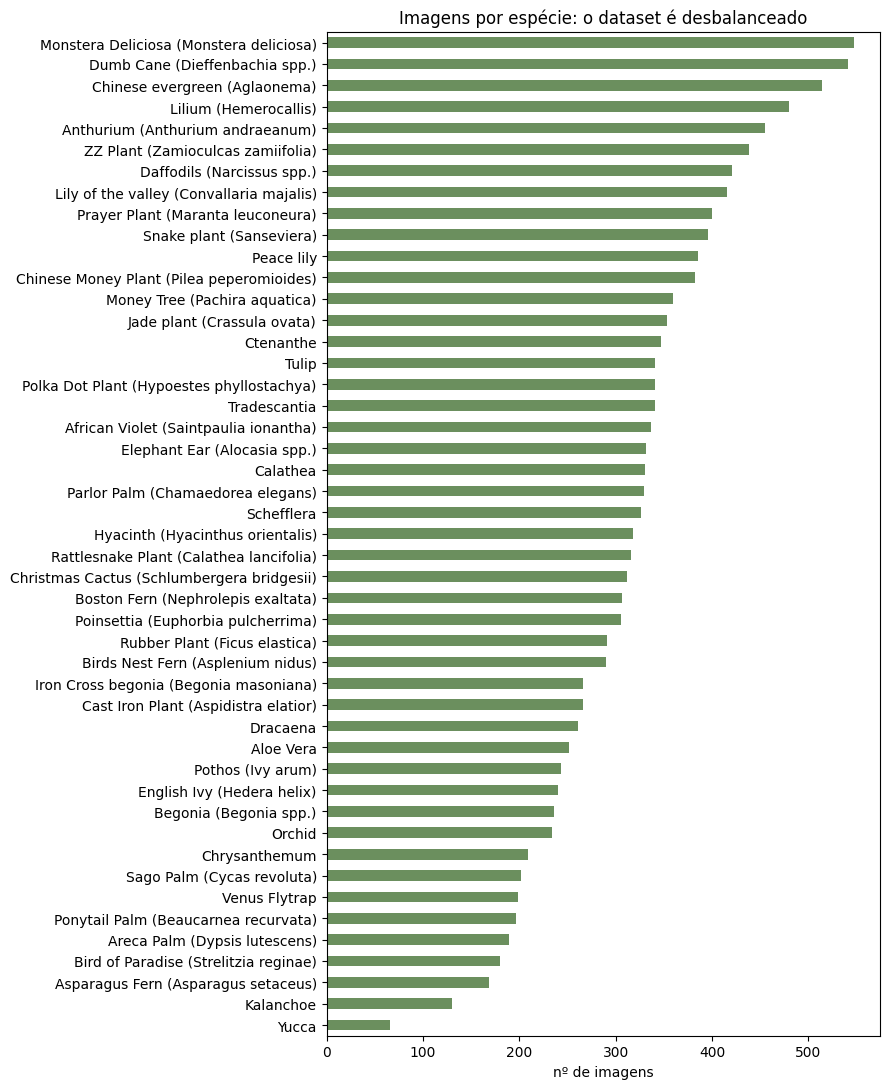

Total: 14790 | menor classe: Yucca (66) | maior: Monstera Deliciosa (Monstera deliciosa) (547)


In [4]:
itens = [(os.path.join(DADOS, c, f), i) for i, c in enumerate(CLASSES) for f in sorted(os.listdir(os.path.join(DADOS, c)))]
contagem = pd.Series(Counter(CLASSES[y] for _, y in itens)).sort_values()

fig, ax = plt.subplots(figsize=(9, 11))
contagem.plot.barh(ax=ax, color="#6b8f5e")
ax.set_title("Imagens por espécie: o dataset é desbalanceado")
ax.set_xlabel("nº de imagens")
plt.tight_layout(); plt.show()
print(f"Total: {len(itens)} | menor classe: {contagem.index[0]} ({contagem.iloc[0]}) | maior: {contagem.index[-1]} ({contagem.iloc[-1]})")

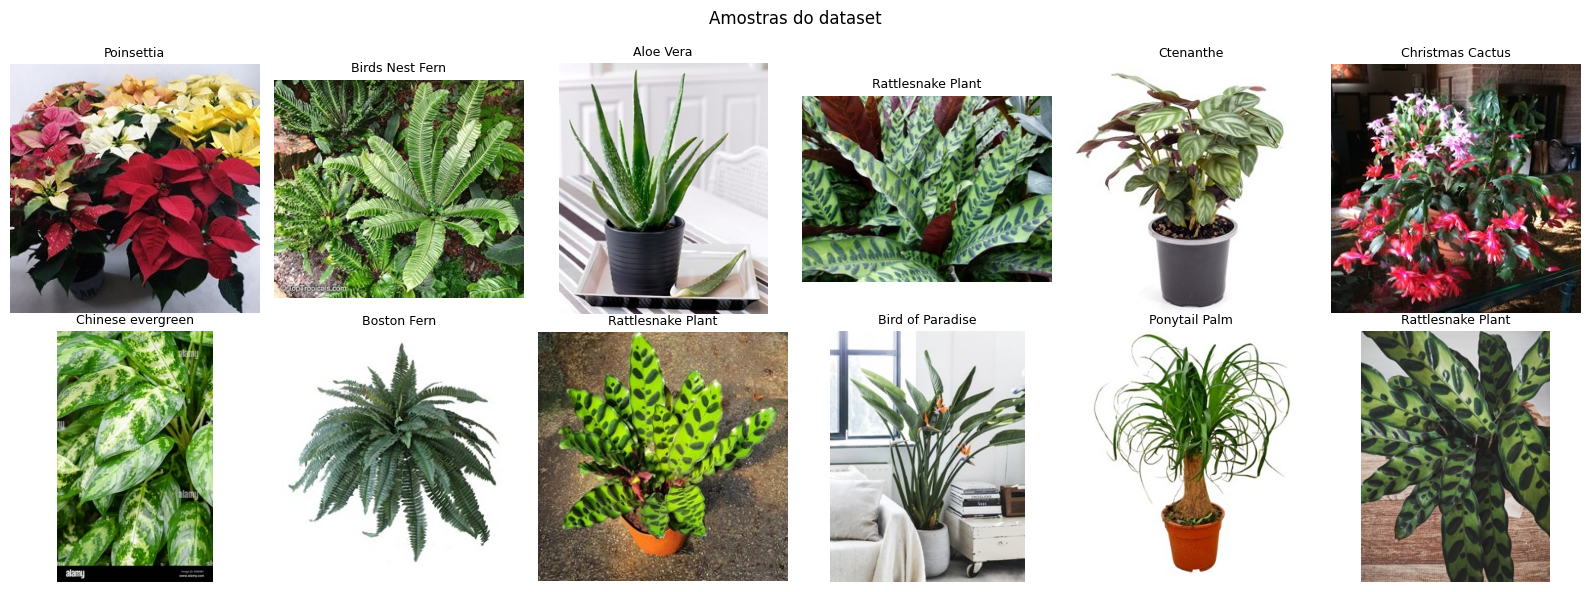

In [5]:
fig, axs = plt.subplots(2, 6, figsize=(16, 6))
for ax, (p, y) in zip(axs.flat, random.sample(itens, 12)):
    ax.imshow(Image.open(p)); ax.set_title(CLASSES[y].split(" (")[0], fontsize=9); ax.axis("off")
plt.suptitle("Amostras do dataset"); plt.tight_layout(); plt.show()

## 3. Machine Learning — CNN com *Transfer Learning*

**Modelo:** EfficientNet-B0 pré-treinada no ImageNet (1,2 milhão de imagens). As camadas convolucionais já sabem extrair bordas, texturas e formas. Nós trocamos só a camada final (1000 classes → 47 espécies).

**Como a CNN "enxerga" a planta:** as primeiras camadas detectam bordas e cores, as do meio detectam texturas e nervuras, e as últimas combinam isso em padrões como "folha recortada com furos" (Monstera). A saída passa por um **softmax**, que vira a probabilidade de cada espécie (ex.: *78% Monstera, 12% Pothos, 10% outras*).

**Treino em 2 fases:**
1. *Backbone* congelado, treina só a cabeça (rápido e estável).
2. *Fine-tuning* da rede inteira com taxa de aprendizado baixa.

**Cuidados técnicos:** divisão estratificada 70/15/15 (treino/validação/teste), *data augmentation* (recorte, espelhamento, cor), perda ponderada pelo tamanho das classes (combate o desbalanceamento), *label smoothing* (reduz excesso de confiança) e precisão mista na GPU.

In [6]:
from sklearn.model_selection import train_test_split

caminhos, rotulos = zip(*itens)
tr_p, tmp_p, tr_y, tmp_y = train_test_split(caminhos, rotulos, test_size=0.30, stratify=rotulos, random_state=CONFIG["SEED"])
va_p, te_p, va_y, te_y = train_test_split(tmp_p, tmp_y, test_size=0.50, stratify=tmp_y, random_state=CONFIG["SEED"])
print(f"Treino: {len(tr_p)} | Validação: {len(va_p)} | Teste: {len(te_p)}")

MEDIA, DESVIO = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
S = CONFIG["IMG_SIZE"]
TF_TREINO = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(), transforms.Normalize(MEDIA, DESVIO)])
TF_AVAL = transforms.Compose([
    transforms.Resize(int(S * 256 / 224)), transforms.CenterCrop(S),
    transforms.ToTensor(), transforms.Normalize(MEDIA, DESVIO)])

class PlantasDS(Dataset):
    def __init__(self, caminhos, rotulos, tf):
        self.c, self.r, self.tf = list(caminhos), list(rotulos), tf
    def __len__(self):
        return len(self.c)
    def __getitem__(self, i):
        return self.tf(Image.open(self.c[i]).convert("RGB")), self.r[i]

kw = dict(batch_size=CONFIG["BATCH"], num_workers=2, pin_memory=(DEVICE == "cuda"))
dl_tr = DataLoader(PlantasDS(tr_p, tr_y, TF_TREINO), shuffle=True, drop_last=True, **kw)
dl_va = DataLoader(PlantasDS(va_p, va_y, TF_AVAL), **kw)
dl_te = DataLoader(PlantasDS(te_p, te_y, TF_AVAL), **kw)

Treino: 10353 | Validação: 2218 | Teste: 2219


In [ ]:
def criar_modelo(n_classes, pretreinado=True):
    pesos = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretreinado else None
    m = models.efficientnet_b0(weights=pesos)
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
    return m.to(DEVICE)

@torch.no_grad()
def prever_loader(model, dl):
    model.eval()
    P, Y = [], []
    for x, y in dl:
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            logits = model(x.to(DEVICE, non_blocking=True))
        P.append(torch.softmax(logits.float(), 1).cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def treinar(model, epocas, lr, so_cabeca, historico):
    for p in model.features.parameters():
        p.requires_grad = not so_cabeca
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epocas * len(dl_tr))
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))
    for ep in range(epocas):
        model.train(); t0 = time.time(); perda = 0
        for x, y in dl_tr:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
                loss = criterio(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            perda += loss.item()
        P, Y = prever_loader(model, dl_va)
        acc = (P.argmax(1) == Y).mean()
        historico.append(dict(fase="cabeça" if so_cabeca else "fine-tuning", perda_treino=perda / len(dl_tr), acc_validacao=acc))
        print(f"[{historico[-1]['fase']}] época {ep + 1}/{epocas} | perda {perda / len(dl_tr):.3f} | acc validação {acc:.3f} | {time.time() - t0:.0f}s")
        if acc >= max(h["acc_validacao"] for h in historico):
            torch.save(dict(estado=model.state_dict(), classes=CLASSES, historico=historico), CKPT)

# perda ponderada: classes raras pesam mais (1/sqrt(frequência))
freq = np.bincount(tr_y, minlength=len(CLASSES))
pesos_classe = torch.tensor((1 / np.sqrt(freq)) / (1 / np.sqrt(freq)).mean(), dtype=torch.float32, device=DEVICE)
criterio = nn.CrossEntropyLoss(weight=pesos_classe, label_smoothing=0.1)

if CONFIG["PULAR_TREINO_SE_EXISTIR"] and os.path.exists(CKPT):
    ck = torch.load(CKPT, map_location=DEVICE)
    assert ck["classes"] == CLASSES, "As classes do checkpoint não batem com os dados."
    model = criar_modelo(len(CLASSES), pretreinado=False)
    model.load_state_dict(ck["estado"]); historico = ck["historico"]
    print("✅ Modelo carregado do Drive, treino pulado. (Para treinar de novo: PULAR_TREINO_SE_EXISTIR=False)")
else:
    model = criar_modelo(len(CLASSES)); historico = []
    t0 = time.time()
    treinar(model, CONFIG["EPOCAS_CABECA"], CONFIG["LR_CABECA"], True, historico)
    treinar(model, CONFIG["EPOCAS_FINE_TUNING"], CONFIG["LR_FINE_TUNING"], False, historico)
    print(f"Treino total: {(time.time() - t0) / 60:.1f} min")
    model.load_state_dict(torch.load(CKPT, map_location=DEVICE)["estado"])  # melhor época
model.eval();

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 109MB/s] 


[cabeça] época 1/2 | perda 3.040 | acc validação 0.697 | 64s
[cabeça] época 2/2 | perda 1.910 | acc validação 0.737 | 58s


In [ ]:
h = pd.DataFrame(historico)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(h.perda_treino, "o-"); ax[0].set_title("Perda no treino"); ax[0].set_xlabel("época")
ax[1].plot(h.acc_validacao, "o-", color="#3c6e47"); ax[1].set_title("Acurácia na validação"); ax[1].set_xlabel("época")
n_cab = (h.fase == "cabeça").sum()
for a in ax: a.axvline(n_cab - 0.5, ls="--", c="gray")
plt.tight_layout(); plt.show()

### 3.1 Avaliação no conjunto de **teste** (imagens nunca vistas)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

P_te, Y_te = prever_loader(model, dl_te)
pred = P_te.argmax(1)
top3 = np.argsort(-P_te, 1)[:, :3]
print(f"Acurácia top-1: {(pred == Y_te).mean():.3f}")
print(f"Acurácia top-3: {np.mean([y in t for y, t in zip(Y_te, top3)]):.3f}")
print(f"F1 macro:       {f1_score(Y_te, pred, average='macro'):.3f}")

nomes_curtos = [c.split(" (")[0] for c in CLASSES]
rel = pd.DataFrame(classification_report(Y_te, pred, target_names=nomes_curtos, output_dict=True, zero_division=0)).T
rel = rel.iloc[:len(CLASSES)].sort_values("f1-score")
display(rel.head(10).style.format("{:.2f}").set_caption("10 espécies com pior desempenho"))

In [ ]:
cm = confusion_matrix(Y_te, pred)
fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Greens")
ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(nomes_curtos, rotation=90, fontsize=7)
ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(nomes_curtos, fontsize=7)
ax.set_xlabel("previsto"); ax.set_ylabel("real"); ax.set_title("Matriz de confusão (normalizada por linha)")
plt.colorbar(im, fraction=0.03); plt.tight_layout(); plt.show()

conf = [(nomes_curtos[i], nomes_curtos[j], cm[i, j]) for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j and cm[i, j] > 0]
display(pd.DataFrame(sorted(conf, key=lambda t: -t[2])[:8], columns=["real", "confundida com", "qtd"]))

## 4. Base de conhecimento de toxicidade + banco de consultas

A base foi compilada a partir da lista **ASPCA — Toxic and Non-Toxic Plants** (American Society for the Prevention of Cruelty to Animals), referência internacional em toxicologia veterinária. Para cada espécie temos o nome canônico, os nomes populares no Brasil, a toxicidade para **gatos** e **cães** (escala 0–3), o princípio tóxico e os sinais clínicos.

| Gravidade | Significado |
|---|---|
| 0 | Não tóxica (pode causar só um leve desconforto se ingerida em grande quantidade) |
| 1 | Leve: irritação, vômito ou diarreia, geralmente autolimitados |
| 2 | Moderada: dor/inchaço oral, vômitos repetidos. Procure o veterinário |
| 3 | **Grave/emergência**: risco de lesão renal, hepática ou cardíaca, ou de morte |

A base também inclui algumas plantas **que o classificador não conhece**, mas que são muito comuns e perigosas no Brasil (espirradeira, copo-de-leite, mamona...). Elas podem ser consultadas pelo nome (Seção 7, aba "Buscar pelo nome").

> ⚠️ Escala indicativa, montada pela equipe para fins acadêmicos. Sempre confira em [aspca.org](https://www.aspca.org/pet-care/animal-poison-control/toxic-and-non-toxic-plants).

In [ ]:
OXALATO = ("Oxalatos de cálcio insolúveis (cristais em forma de agulha)",
           "Irritação e dor intensas na boca, lábios e língua; salivação excessiva; vômito; dificuldade para engolir. Raramente, inchaço das vias aéreas.")
SAPONINA = "Saponinas"

def P(chave, canonico, cientifico, nomes_pt, gatos, caes, principio, sintomas, chaves_pasta, no_classificador=True):
    return dict(chave=chave, nome_canonico=canonico, cientifico=cientifico, nomes_pt=nomes_pt, gatos=gatos, caes=caes,
                principio=principio, sintomas=sintomas, chaves_pasta=chaves_pasta, no_classificador=no_classificador)

NT = ("—", "Não tóxica segundo a ASPCA.")
KB = [
    P("african_violet", "African Violet", "Saintpaulia ionantha", ["violeta-africana", "violeta"], 0, 0, *NT, ["african violet", "saintpaulia"]),
    P("aloe_vera", "Aloe", "Aloe vera", ["babosa", "aloe vera"], 1, 1, "Saponinas e antraquinonas", "Vômito, letargia, diarreia.", ["aloe"]),
    P("anthurium", "Flamingo Flower", "Anthurium andraeanum", ["antúrio"], 2, 2, *OXALATO, ["anthurium"]),
    P("areca_palm", "Areca Palm", "Dypsis lutescens", ["palmeira-areca", "areca-bambu"], 0, 0, *NT, ["areca"]),
    P("asparagus_fern", "Asparagus Fern", "Asparagus setaceus", ["aspargo-samambaia", "melindro", "aspargo-plumoso"], 1, 1, "Sapogeninas", "Contato: dermatite alérgica. Ingestão de frutos: vômito, diarreia, dor abdominal.", ["asparagus"]),
    P("begonia", "Begonia", "Begonia spp.", ["begônia"], 1, 1, "Oxalatos de cálcio insolúveis (tubérculos são a parte mais tóxica)", "Irritação oral, salivação, vômito.", ["begonia"]),
    P("bird_of_paradise", "Bird of Paradise Flower", "Strelitzia reginae", ["ave-do-paraíso", "estrelítzia"], 1, 1, "Não bem definido", "Náusea leve, vômito, sonolência.", ["bird of paradise", "strelitzia"]),
    P("birds_nest_fern", "Bird's Nest Fern", "Asplenium nidus", ["asplênio", "ninho-de-passarinho"], 0, 0, *NT, ["nest fern", "asplenium"]),
    P("boston_fern", "Boston Fern", "Nephrolepis exaltata", ["samambaia", "samambaia-americana", "samambaia-de-boston"], 0, 0, *NT, ["boston fern", "nephrolepis"]),
    P("calathea", "Calathea", "Calathea / Goeppertia spp.", ["calateia"], 0, 0, *NT, ["calathea"]),
    P("cast_iron_plant", "Cast Iron Plant", "Aspidistra elatior", ["aspidistra", "planta-de-ferro"], 0, 0, *NT, ["cast iron", "aspidistra"]),
    P("chinese_evergreen", "Chinese Evergreen", "Aglaonema modestum", ["aglaonema", "café-de-salão"], 2, 2, *OXALATO, ["chinese evergreen", "aglaonema"]),
    P("chinese_money_plant", "Chinese Money Plant", "Pilea peperomioides", ["pilea", "planta-dinheiro-chinesa", "planta-moeda"], 0, 0, "—", "Considerada não tóxica.", ["chinese money", "pilea"]),
    P("christmas_cactus", "Christmas Cactus", "Schlumbergera bridgesii", ["flor-de-maio", "cacto-de-natal"], 0, 0, *NT, ["christmas cactus", "schlumbergera"]),
    P("chrysanthemum", "Chrysanthemum", "Chrysanthemum spp.", ["crisântemo"], 1, 1, "Lactonas sesquiterpênicas, piretrinas", "Vômito, diarreia, salivação, falta de coordenação, dermatite.", ["chrysanthemum"]),
    P("ctenanthe", "Ctenanthe", "Ctenanthe spp.", ["ctenanthe"], 0, 0, "—", "Considerada não tóxica (família Marantaceae, a mesma da maranta e da calateia).", ["ctenanthe"]),
    P("daffodil", "Daffodil", "Narcissus spp.", ["narciso"], 2, 2, "Licorina e outros alcaloides (bulbo é a parte mais tóxica)", "Vômito, salivação, diarreia. Em grande quantidade: convulsões, queda de pressão, arritmia.", ["daffodil", "narcissus"]),
    P("dracaena", "Dracaena", "Dracaena spp.", ["dracena", "pau-d'água", "coqueiro-de-vênus"], 1, 1, SAPONINA, "Vômito (às vezes com sangue), apatia, falta de apetite, salivação. Em gatos: pupilas dilatadas.", ["dracaena"]),
    P("dumb_cane", "Dieffenbachia", "Dieffenbachia spp.", ["comigo-ninguém-pode"], 2, 2, *OXALATO, ["dumb cane", "dieffenbachia"]),
    P("elephant_ear", "Elephant Ear", "Alocasia / Colocasia spp.", ["orelha-de-elefante", "alocásia", "taioba-brava"], 2, 2, *OXALATO, ["elephant ear", "alocasia"]),
    P("english_ivy", "English Ivy", "Hedera helix", ["hera", "hera-inglesa"], 1, 1, "Saponinas triterpênicas", "Vômito, dor abdominal, salivação, diarreia.", ["english ivy", "hedera"]),
    P("hyacinth", "Hyacinth", "Hyacinthus orientalis", ["jacinto"], 2, 2, "Lactonas alergênicas (bulbo é a parte mais tóxica)", "Vômito intenso, diarreia, salivação, às vezes com sangue.", ["hyacinth"]),
    P("iron_cross_begonia", "Begonia (Iron Cross)", "Begonia masoniana", ["begônia-cruz-de-ferro"], 1, 1, "Oxalatos de cálcio insolúveis", "Irritação oral, salivação, vômito.", ["iron cross"]),
    P("jade_plant", "Jade Plant", "Crassula ovata", ["planta-jade", "árvore-da-amizade", "bálsamo"], 1, 1, "Desconhecido", "Vômito, apatia, falta de coordenação.", ["jade"]),
    P("kalanchoe", "Kalanchoe", "Kalanchoe spp.", ["calanchoê", "flor-da-fortuna"], 2, 2, "Bufadienolídeos (glicosídeos cardíacos)", "Vômito, diarreia. Raramente: alterações no ritmo cardíaco.", ["kalanchoe"]),
    P("lilium", "Lily", "Lilium spp.", ["lírio", "lírio-asiático", "lírio-oriental"], 3, 1, "Desconhecido (toda a planta, inclusive pólen e a água do vaso)",
      "GATOS: insuficiência renal aguda, mesmo com pequena ingestão. Vômito, apatia, falta de apetite; lesão renal em 24–72 h. CÃES: geralmente só desconforto gastrointestinal leve.", ["lilium", "lily (lilium"]),
    P("lily_of_the_valley", "Lily-of-the-Valley", "Convallaria majalis", ["lírio-do-vale", "convalária"], 3, 3, "Glicosídeos cardíacos", "Vômito, arritmia cardíaca, pressão baixa, desorientação, convulsões, coma.", ["lily of the valley", "convallaria"]),
    P("money_tree", "Money Tree", "Pachira aquatica", ["munguba", "pachira", "árvore-do-dinheiro"], 0, 0, *NT, ["money tree", "pachira"]),
    P("monstera", "Monstera", "Monstera deliciosa", ["costela-de-adão", "monstera"], 2, 2, *OXALATO, ["monstera"]),
    P("orchid", "Moth Orchid", "Phalaenopsis spp.", ["orquídea", "orquídea-borboleta"], 0, 0, *NT, ["orchid", "phalaenopsis"]),
    P("parlor_palm", "Parlor Palm", "Chamaedorea elegans", ["palmeira-camedórea", "palmeirinha-de-salão"], 0, 0, *NT, ["parlor palm", "chamaedorea"]),
    P("peace_lily", "Peace Lily", "Spathiphyllum spp.", ["lírio-da-paz", "espatifilo"], 2, 2, *OXALATO[:1],
      OXALATO[1] + " Atenção: apesar do nome, NÃO é um lírio verdadeiro e não causa a lesão renal dos lírios.", ["peace lily", "spathiphyllum"]),
    P("poinsettia", "Poinsettia", "Euphorbia pulcherrima", ["bico-de-papagaio", "flor-do-natal", "poinsétia"], 1, 1, "Seiva leitosa irritante", "Irritação da boca e do estômago, às vezes vômito. Toxicidade geralmente exagerada.", ["poinsettia"]),
    P("polka_dot_plant", "Polka Dot Plant", "Hypoestes phyllostachya", ["planta-sardenta", "confete"], 0, 0, *NT, ["polka dot", "hypoestes"]),
    P("ponytail_palm", "Ponytail Palm", "Beaucarnea recurvata", ["pata-de-elefante", "nolina"], 0, 0, *NT, ["ponytail", "beaucarnea"]),
    P("pothos", "Golden Pothos", "Epipremnum aureum", ["jiboia", "pothos"], 2, 2, *OXALATO, ["pothos", "epipremnum"]),
    P("prayer_plant", "Prayer Plant", "Maranta leuconeura", ["maranta", "planta-rezadeira"], 0, 0, *NT, ["prayer plant", "maranta"]),
    P("rattlesnake_plant", "Rattlesnake Plant", "Goeppertia insignis (Calathea lancifolia)", ["calateia-cascavel", "maranta-cascavel"], 0, 0, *NT, ["rattlesnake plant", "rattlesnake"]),
    P("rubber_plant", "Indian Rubber Plant", "Ficus elastica", ["falsa-seringueira", "fícus-elástica"], 1, 1, "Seiva irritante (ficina)", "Irritação gastrointestinal e de pele.", ["rubber plant", "ficus elastica"]),
    P("sago_palm", "Sago Palm", "Cycas revoluta", ["cica", "sagu-de-jardim", "palmeira-sagu"], 3, 3, "Cicasina (sementes são a parte mais tóxica)", "Vômito, fezes escuras, icterícia, sede, sangramentos, insuficiência hepática. Pode ser fatal.", ["sago", "cycas"]),
    P("schefflera", "Schefflera", "Schefflera / Heptapleurum spp.", ["cheflera", "árvore-guarda-chuva"], 2, 2, "Oxalatos de cálcio insolúveis e saponinas", OXALATO[1], ["schefflera"]),
    P("snake_plant", "Snake Plant", "Dracaena trifasciata (Sansevieria)", ["espada-de-são-jorge", "espada-de-santa-bárbara", "sansevieria"], 1, 1, SAPONINA, "Náusea, vômito, diarreia.", ["snake plant", "sansevi"]),
    P("tradescantia", "Wandering Jew / Inch Plant", "Tradescantia spp.", ["trapoeraba", "lambari", "tradescância"], 1, 1, "Seiva irritante", "Dermatite (irritação de pele), principalmente em cães.", ["tradescantia"]),
    P("tulip", "Tulip", "Tulipa spp.", ["tulipa"], 2, 2, "Tulipalina A e B (bulbo é a parte mais tóxica)", "Vômito, apatia, diarreia, salivação.", ["tulip"]),
    P("venus_flytrap", "Venus Flytrap", "Dionaea muscipula", ["dioneia", "papa-moscas"], 0, 0, *NT, ["venus", "dionaea"]),
    P("yucca", "Yucca", "Yucca spp.", ["iúca", "mandioca-gigante"], 1, 1, SAPONINA, "Vômito, diarreia.", ["yucca"]),
    P("zz_plant", "ZZ Plant", "Zamioculcas zamiifolia", ["zamioculca", "zz"], 1, 1, "Oxalatos de cálcio (não listada individualmente pela ASPCA)", "Irritação oral, salivação, vômito.", ["zz plant", "zamioculcas"]),
    # --- Fora do classificador: comuns e perigosas no Brasil (consulta por nome) ---
    P("oleander", "Oleander", "Nerium oleander", ["espirradeira", "oleandro"], 3, 3, "Glicosídeos cardíacos", "Vômito, diarreia, arritmia grave, hipotermia. Pode ser fatal.", [], False),
    P("calla_lily", "Calla Lily", "Zantedeschia aethiopica", ["copo-de-leite"], 2, 2, *OXALATO, [], False),
    P("azalea", "Azalea", "Rhododendron spp.", ["azaleia", "azálea"], 3, 3, "Grayanotoxinas", "Vômito, diarreia, fraqueza, alterações cardíacas, coma.", [], False),
    P("caladium", "Caladium", "Caladium spp.", ["tinhorão", "caládio"], 2, 2, *OXALATO, [], False),
    P("crown_of_thorns", "Crown of Thorns", "Euphorbia milii", ["coroa-de-cristo", "dois-amigos"], 1, 1, "Seiva irritante", "Vômito, diarreia, irritação na boca e na pele.", [], False),
    P("castor_bean", "Castor Bean", "Ricinus communis", ["mamona", "carrapateira"], 3, 3, "Ricina (sementes)", "Dor abdominal, vômito e diarreia com sangue, desidratação, convulsões. Pode ser fatal.", [], False),
]
KB_POR_CHAVE = {k["chave"]: k for k in KB}

def chave_da_classe(nome_pasta):
    # Liga o nome da pasta do dataset à entrada da base (casa a palavra-chave mais longa).
    n = nome_pasta.lower()
    melhor = max(((len(c), k["chave"]) for k in KB for c in k["chaves_pasta"] if c in n), default=None)
    return melhor[1] if melhor else None

MAPA_CLASSE_KB = {c: chave_da_classe(c) for c in CLASSES}
sem_par = [c for c, k in MAPA_CLASSE_KB.items() if k is None]
print(f"{len(CLASSES) - len(sem_par)}/{len(CLASSES)} classes ligadas à base de toxicidade.")
if sem_par:
    print("⚠️ Sem correspondência (serão tratadas como 'toxicidade desconhecida'):", sem_par)

In [ ]:
# Banco de dados das consultas (sistema externo de registro/auditoria)
# PRIVACIDADE: a foto NÃO é armazenada, só um hash irreversível + o resultado.
con = sqlite3.connect(DB_PATH, check_same_thread=False)
con.execute('''CREATE TABLE IF NOT EXISTS consultas (
    id INTEGER PRIMARY KEY AUTOINCREMENT, quando TEXT, hash_imagem TEXT, animal TEXT, ja_ingeriu INTEGER,
    especie TEXT, confianca REAL, decisao TEXT, toxica INTEGER, backend_llm TEXT)''')
con.commit()

def registrar(r):
    con.execute("INSERT INTO consultas (quando, hash_imagem, animal, ja_ingeriu, especie, confianca, decisao, toxica, backend_llm) VALUES (?,?,?,?,?,?,?,?,?)",
                (datetime.datetime.now().isoformat(timespec="seconds"), r.get("hash"), r["animal"], int(r["ja_ingeriu"]),
                 r.get("chave"), r.get("confianca"), r["decisao"], None if r.get("gravidade") is None else int(r["gravidade"] > 0), LLM_CLIENTE.backend))
    con.commit()

## 5. Integração com LLM

O LLM entra em **cinco pontos** do sistema:

| Função | O que faz | Proteção contra erro/alucinação |
|---|---|---|
| `normalizar_nome` | Converte "lírio-da-paz", "costela de adão" ou um erro de digitação no nome canônico da ASPCA | A resposta do LLM precisa ser uma chave **existente** na base; senão é descartada |
| `explicar_toxicidade` | Transforma a ficha técnica em linguagem natural | O prompt manda usar **somente** os dados da ficha (*grounding*) |
| `orientar_emergencia` | O que fazer se o animal já ingeriu a planta | Passos de segurança fixos são sempre exibidos, com ou sem LLM |
| `decidir_baixa_confianca` | Decide entre pedir nova foto e entregar resultado parcial | Regras de limiar têm a palavra final (o LLM não pode "aumentar" a confiança) |
| `conversar` | Responde perguntas sobre a planta identificada | Responde com base na ficha e encaminha ao veterinário |

**Qual LLM?** O código tenta, nesta ordem:
1. **Gemini API** (gratuita): crie uma chave em [aistudio.google.com/apikey](https://aistudio.google.com/apikey) e salve em 🔑 **Secrets** do Colab (ícone de chave na barra lateral) com o nome `GEMINI_API_KEY`, ativando o acesso ao notebook.
2. **Colab AI** (`google.colab.ai`): Gemini embutido no Colab, sem chave, quando disponível na sua conta.
3. **Modo offline**: respostas por *template* a partir da base. O sistema **nunca para de funcionar** por falta de LLM, o que é importante para a demonstração.

In [ ]:
class ClienteLLM:
    MODELOS_GEMINI = ["gemini-flash-latest", "gemini-2.5-flash", "gemini-2.0-flash"]

    def __init__(self):
        self.backend, self.modelo = "offline", None
        chave = None
        try:
            from google.colab import userdata
            chave = userdata.get("GEMINI_API_KEY")
        except Exception:
            chave = os.environ.get("GEMINI_API_KEY")
        if chave:
            try:
                from google import genai
                self.cliente = genai.Client(api_key=chave)
                self.backend = "gemini-api"
            except Exception as e:
                print("Falha ao iniciar Gemini API:", e)
        if self.backend == "offline":
            try:
                from google.colab import ai
                self.colab_ai = ai
                self.backend = "colab-ai"
            except Exception:
                pass

    def gerar(self, prompt, sistema="", json_mode=False, temperatura=0.2):
        # Retorna o texto do LLM ou None (o chamador usa o fallback offline).
        try:
            if self.backend == "gemini-api":
                from google.genai import types
                cfg = types.GenerateContentConfig(system_instruction=sistema or None, temperature=temperatura,
                                                  response_mime_type="application/json" if json_mode else None)
                for m in ([self.modelo] if self.modelo else self.MODELOS_GEMINI):
                    try:
                        r = self.cliente.models.generate_content(model=m, contents=prompt, config=cfg)
                        self.modelo = m
                        return r.text
                    except Exception as e:
                        ultimo = e
                raise ultimo
            if self.backend == "colab-ai":
                extra = "\nResponda APENAS com JSON válido, sem markdown." if json_mode else ""
                return self.colab_ai.generate_text(f"{sistema}\n\n{prompt}{extra}")
        except Exception as e:
            print(f"[LLM indisponível nesta chamada: {type(e).__name__}] usando modo offline.")
        return None

LLM_CLIENTE = ClienteLLM()
print("Backend de LLM:", LLM_CLIENTE.backend)

def json_do_llm(txt):
    if not txt:
        return None
    m = re.search(r"\{.*\}", txt, re.S)
    try:
        return json.loads(m.group(0)) if m else None
    except Exception:
        return None

In [ ]:
ANIMAL_TXT = {"gato": "gatos", "cachorro": "cães"}
ROTULO_GRAV = {0: "não tóxica", 1: "toxicidade leve", 2: "toxicidade moderada", 3: "TOXICIDADE GRAVE"}

def sem_acento(s):
    return "".join(c for c in unicodedata.normalize("NFD", s.lower()) if unicodedata.category(c) != "Mn").replace("-", " ").strip()

def gravidade(planta, animal):
    return planta["gatos"] if animal == "gato" else planta["caes"]

def ficha_texto(p):
    return (f"Nome canônico ASPCA: {p['nome_canonico']} | Científico: {p['cientifico']} | Nomes populares: {', '.join(p['nomes_pt'])}\n"
            f"Gravidade para gatos: {p['gatos']} ({ROTULO_GRAV[p['gatos']]}) | para cães: {p['caes']} ({ROTULO_GRAV[p['caes']]})\n"
            f"Princípio tóxico: {p['principio']}\nSinais clínicos: {p['sintomas']}")

# ---------- 1) Normalização de nome ----------
_INDICE_NOMES = {}
for p in KB:
    for n in p["nomes_pt"] + [p["nome_canonico"], p["cientifico"], p["chave"].replace("_", " ")]:
        _INDICE_NOMES[sem_acento(n)] = p["chave"]

def normalizar_nome(texto):
    # Recebe um nome livre (ex.: 'lírio-da-paz') e devolve a chave canônica da base, ou None.
    t = sem_acento(texto)
    if t in _INDICE_NOMES:
        return _INDICE_NOMES[t], "regra (match exato)"
    lista = "\n".join(f"- {p['chave']}: {p['nome_canonico']} / {p['cientifico']} / {', '.join(p['nomes_pt'])}" for p in KB)
    r = json_do_llm(LLM_CLIENTE.gerar(
        f"Nome informado pelo usuário: \"{texto}\"\n\nLista de plantas da base:\n{lista}\n\n"
        "Qual chave corresponde a essa planta? Considere sinônimos, nomes regionais do Brasil, inglês e erros de digitação. "
        "Se a planta NÃO está na lista, use null. Responda em JSON: {\"chave\": \"...\" ou null, \"justificativa\": \"...\"}",
        sistema="Você é um botânico que mapeia nomes populares para uma lista fechada de espécies. Nunca invente chaves.",
        json_mode=True))
    if r is not None:
        k = r.get("chave")
        return (k, "LLM") if k in KB_POR_CHAVE else (None, "LLM (fora da base)")
    parecido = difflib.get_close_matches(t, list(_INDICE_NOMES), n=1, cutoff=0.75)
    return (_INDICE_NOMES[parecido[0]], "regra (aproximado)") if parecido else (None, "não encontrado")

# ---------- 2) Explicação da toxicidade ----------
SISTEMA_SEGURANCA = ("Você é um assistente de segurança para tutores de animais de estimação, no Brasil. "
                     "Use EXCLUSIVAMENTE as informações da FICHA fornecida; não invente substâncias, sintomas ou doses. "
                     "Se algo não estiver na ficha, diga que não há essa informação. Seja claro, calmo e direto. "
                     "Termine lembrando que a orientação não substitui um médico-veterinário. Português do Brasil.")

def explicar_toxicidade(p, animal):
    g = gravidade(p, animal)
    txt = LLM_CLIENTE.gerar(
        f"FICHA:\n{ficha_texto(p)}\n\nExplique para um tutor de {ANIMAL_TXT[animal]}, em até 110 palavras, se essa planta é perigosa, "
        "por quê (princípio tóxico, em linguagem simples), quais sinais observar e um cuidado prático para evitar acidentes.",
        sistema=SISTEMA_SEGURANCA)
    if txt:
        return txt.strip()
    if g == 0:
        return (f"**{p['nome_canonico']}** é considerada **não tóxica** para {ANIMAL_TXT[animal]}. Se o animal comer muito, pode ter um "
                "desconforto leve (vômito ocasional). _Esta orientação não substitui um médico-veterinário._")
    return (f"**{p['nome_canonico']}** é **tóxica** para {ANIMAL_TXT[animal]} ({ROTULO_GRAV[g]}). Princípio tóxico: {p['principio']}. "
            f"Sinais: {p['sintomas']} Mantenha a planta fora do alcance do animal. _Esta orientação não substitui um médico-veterinário._")

# ---------- 3) Orientação de emergência ----------
PASSOS_FIXOS = [
    "Afaste o animal da planta e retire com cuidado os pedaços que estiverem na boca.",
    "**Não induza vômito** e não dê leite, óleo, sal ou remédios caseiros sem orientação veterinária.",
    "Ligue para um veterinário ou hospital veterinário 24h **agora** e informe a planta, a quantidade e o horário aproximados.",
    "Leve uma foto ou um pedaço da planta (e a embalagem, se houver) para a consulta.",
]

def orientar_emergencia(p, animal):
    g = gravidade(p, animal) if p else None
    passos = "\n".join(f"{i}. {s}" for i, s in enumerate(PASSOS_FIXOS, 1))
    if p is not None and g == 0:
        cab = (f"✅ **{p['nome_canonico']}** não é considerada tóxica. Observe o animal nas próximas horas. "
               "Se houver vômito persistente, apatia ou qualquer sinal estranho, procure o veterinário.")
        return cab
    urg = "🚨 **EMERGÊNCIA — vá ao veterinário imediatamente, mesmo que o animal pareça bem.**" if (g is None or g >= 2) else \
          "⚠️ **Procure orientação veterinária hoje.**"
    extra = LLM_CLIENTE.gerar(
        f"FICHA:\n{ficha_texto(p) if p else 'Espécie não identificada com segurança.'}\n\nO {animal} do usuário JÁ INGERIU esta planta. "
        "Em até 70 palavras, diga quais sinais específicos observar no caminho até o veterinário e por quê o atendimento rápido importa "
        "para essa planta. Não repita instruções genéricas de primeiros socorros.", sistema=SISTEMA_SEGURANCA)
    if not extra and p is not None:
        extra = f"Sinais a observar: {p['sintomas']}"
    if p is not None and p["chave"] == "lilium" and animal == "gato":
        extra = (extra or "") + "\n\n**Lírios em gatos:** a lesão renal pode aparecer só em 24–72 h. O tratamento precoce (nas primeiras horas) é o que salva o animal."
    return f"{urg}\n\n{passos}\n\n{extra or ''}"

# ---------- 4) Decisão em baixa confiança ----------
def decidir_baixa_confianca(top, animal):
    # Regras definem os limites; o LLM escolhe e redige dentro deles.
    p1, p2 = top[0][1], top[1][1]
    if p1 >= CONFIG["LIMIAR_CONFIANCA"] and (p1 - p2) >= CONFIG["LIMIAR_MARGEM"]:
        return "confiante", None
    permitido = ["pedir_nova_foto"] if p1 < CONFIG["LIMIAR_MINIMO"] else ["pedir_nova_foto", "resultado_parcial"]
    cand = []
    for nome, prob in top:
        k = MAPA_CLASSE_KB.get(nome); p = KB_POR_CHAVE.get(k)
        cand.append(f"- {nome}: {prob:.0%} | {'toxicidade desconhecida' if p is None else ROTULO_GRAV[gravidade(p, animal)]} para {ANIMAL_TXT[animal]}")
    r = json_do_llm(LLM_CLIENTE.gerar(
        "O classificador de imagens está inseguro. Candidatos (top-3):\n" + "\n".join(cand) +
        f"\n\nAções permitidas: {permitido}. Escolha a ação e escreva uma mensagem curta (até 70 palavras) para o usuário. "
        "Se algum candidato for tóxico, aplique o princípio da precaução e avise. Se pedir nova foto, dê 2 dicas concretas de como fotografar. "
        "JSON: {\"acao\": \"...\", \"mensagem\": \"...\"}", sistema=SISTEMA_SEGURANCA, json_mode=True))
    if r and r.get("acao") in permitido and r.get("mensagem"):
        return r["acao"], r["mensagem"]
    acao = permitido[-1]
    msg = ("Não tenho certeza da espécie. " +
           ("Tente outra foto: folha inteira, bem iluminada, fundo neutro, sem filtro." if acao == "pedir_nova_foto"
            else "Mostro as possibilidades mais prováveis abaixo. Por precaução, considere o pior caso entre elas."))
    return acao, msg

# ---------- 5) Conversa ----------
def conversar(pergunta, chave, animal):
    p = KB_POR_CHAVE.get(chave) if chave else None
    if p is None:
        return "Primeiro identifique uma planta (pela foto ou pelo nome) para eu poder responder sobre ela."
    txt = LLM_CLIENTE.gerar(f"FICHA:\n{ficha_texto(p)}\n\nO tutor tem um {animal}. Pergunta: {pergunta}\n"
                            "Responda em até 120 palavras. Se a pergunta for sobre cuidados de cultivo (rega, luz), pode usar "
                            "conhecimento geral de jardinagem, mas para toxicidade use só a ficha.", sistema=SISTEMA_SEGURANCA, temperatura=0.4)
    return txt.strip() if txt else f"(modo offline) Informações disponíveis:\n\n{ficha_texto(p)}"

In [ ]:
# Teste rápido das funções de LLM
for nome in ["lírio-da-paz", "costela de adao", "espada de sao jorge", "jibóia", "espirradeira", "samambaia-de-metro", "mamona"]:
    k, via = normalizar_nome(nome)
    print(f"{nome:22s} → {str(k):20s} via {via}")

display(Markdown("---\n**Exemplo de explicação (Monstera, gato):**\n\n" + explicar_toxicidade(KB_POR_CHAVE["monstera"], "gato")))

## 6. Pipeline completo: Entrada → Processamento → Saída

```
foto ─▶ classificar (CNN, top-3) ─▶ decidir_baixa_confianca ─▶ normalizar (classe → chave ASPCA)
     ─▶ lookup na base ─▶ explicar_toxicidade / orientar_emergencia (LLM) ─▶ resposta + registro no SQLite
```

In [ ]:
@torch.no_grad()
def classificar(img, k=3):
    x = TF_AVAL(img.convert("RGB")).unsqueeze(0).to(DEVICE)
    probs = torch.softmax(model(x).float(), 1)[0].cpu()
    v, i = probs.topk(k)
    return [(CLASSES[j], float(p)) for p, j in zip(v, i)]

def analisar_foto(img, animal="gato", ja_ingeriu=False):
    r = dict(animal=animal, ja_ingeriu=ja_ingeriu)
    r["hash"] = hashlib.sha256(img.tobytes()).hexdigest()[:16]
    r["top3"] = classificar(img)
    r["decisao"], msg_incerteza = decidir_baixa_confianca(r["top3"], animal)
    nome, conf = r["top3"][0]
    r["chave"], r["confianca"] = MAPA_CLASSE_KB.get(nome), conf
    p = KB_POR_CHAVE.get(r["chave"])
    partes = []

    if r["decisao"] == "pedir_nova_foto":
        r["gravidade"] = None
        partes.append(f"### 📷 Preciso de outra foto\n{msg_incerteza}")
        if ja_ingeriu:
            partes.append(orientar_emergencia(None, animal))
    else:
        # princípio da precaução: em resultado parcial, considera a maior gravidade entre os candidatos
        gravs = [gravidade(KB_POR_CHAVE[MAPA_CLASSE_KB[n]], animal) if MAPA_CLASSE_KB.get(n) else 3 for n, _ in r["top3"]]
        g = gravidade(p, animal) if p else 3
        r["gravidade"] = max(gravs) if r["decisao"] == "resultado_parcial" else g
        tox = "🟢 **NÃO tóxica**" if r["gravidade"] == 0 else f"🔴 **TÓXICA** ({ROTULO_GRAV[r['gravidade']]})"
        titulo = f"### 🌿 {p['nome_canonico'] if p else nome} — _{p['cientifico'] if p else ''}_"
        if p: titulo += f"\nNomes populares: {', '.join(p['nomes_pt'])}"
        partes.append(titulo)
        if r["decisao"] == "resultado_parcial":
            linhas = "\n".join(f"- {n.split(' (')[0]} ({q:.0%}): " + ("🟢 não tóxica" if gv == 0 else f"🔴 {ROTULO_GRAV[gv]}")
                               for (n, q), gv in zip(r["top3"], gravs))
            partes.append(f"⚠️ **Resultado parcial ({conf:.0%} de confiança).** {msg_incerteza}\n\nPossibilidades:\n{linhas}")
            if r["gravidade"] > 0:
                tox = (f"⚠️ **TRATE COMO POSSIVELMENTE TÓXICA** ({ROTULO_GRAV[r['gravidade']]}), "
                       "porque pelo menos uma das possibilidades é tóxica (princípio da precaução)")
        partes.append(f"**Para {ANIMAL_TXT[animal]}:** {tox}")
        if ja_ingeriu:
            # se a espécie é incerta e algum candidato é tóxico, trata como emergência (espécie desconhecida)
            incerto = r["decisao"] == "resultado_parcial" and r["gravidade"] > 0
            partes.append(orientar_emergencia(None if incerto else p, animal))
        elif p:
            partes.append(explicar_toxicidade(p, animal))
    partes.append(f"<sub>Modelo: EfficientNet-B0 · LLM: {LLM_CLIENTE.backend} · Fonte: ASPCA. "
                  "Esta ferramenta pode errar e **não substitui um médico-veterinário**.</sub>")
    r["resposta"] = "\n\n".join(partes)
    registrar(r)
    return r

def analisar_nome(texto, animal="gato", ja_ingeriu=False):
    k, via = normalizar_nome(texto)
    p = KB_POR_CHAVE.get(k)
    if p is None:
        return None, (f"Não encontrei **{texto}** na base. Isso **não** significa que é segura: trate como potencialmente tóxica "
                      "e confira em aspca.org ou com um veterinário.")
    g = gravidade(p, animal)
    tox = "🟢 **NÃO tóxica**" if g == 0 else f"🔴 **TÓXICA** ({ROTULO_GRAV[g]})"
    corpo = orientar_emergencia(p, animal) if ja_ingeriu else explicar_toxicidade(p, animal)
    nota = "" if p["no_classificador"] else "\n\n_Obs.: esta espécie está na base de toxicidade, mas o modelo de imagem ainda não a reconhece por foto._"
    return k, (f"### 🌿 {p['nome_canonico']} — _{p['cientifico']}_\nReconhecido como **{p['nomes_pt'][0]}** (via {via}).\n\n"
               f"**Para {ANIMAL_TXT[animal]}:** {tox}\n\n{corpo}{nota}")

In [ ]:
# Demonstração com 3 fotos do conjunto de TESTE
for idx in random.sample(range(len(te_p)), 3):
    img = Image.open(te_p[idx])
    r = analisar_foto(img, animal="gato")
    plt.figure(figsize=(3, 3)); plt.imshow(img); plt.axis("off")
    plt.title(f"Real: {CLASSES[te_y[idx]].split(' (')[0]}", fontsize=9); plt.show()
    display(Markdown(r["resposta"] + "\n\n---"))

In [ ]:
# Cenário de emergência: o gato JÁ comeu a planta
idx = next((i for i, y in enumerate(te_y) if MAPA_CLASSE_KB.get(CLASSES[y]) in ("lilium", "dumb_cane", "pothos", "monstera")), 0)
img = Image.open(te_p[idx])
plt.figure(figsize=(3, 3)); plt.imshow(img); plt.axis("off"); plt.show()
display(Markdown(analisar_foto(img, animal="gato", ja_ingeriu=True)["resposta"]))

In [ ]:
# Teste com a SUA foto (envie uma imagem do computador ou do celular)
try:
    from google.colab import files
    enviados = files.upload()
    for nome, dados in enviados.items():
        img = Image.open(io.BytesIO(dados))
        img = ImageOps.exif_transpose(img)
        plt.figure(figsize=(3, 3)); plt.imshow(img); plt.axis("off"); plt.show()
        display(Markdown(analisar_foto(img, animal="gato")["resposta"]))
except Exception as e:
    print("Upload não disponível aqui:", e)

## 7. Interface web (aplicativo de demonstração)

A célula abaixo abre um app com **Gradio**. O link público (`*.gradio.live`) pode ser aberto **no celular**: dá para tirar a foto da planta na hora, durante a apresentação.

Abas:
- **📷 Identificar pela foto**: entrada principal (câmera ou galeria).
- **💬 Perguntar sobre a planta**: conversa com o LLM sobre a última planta identificada.
- **🔤 Buscar pelo nome**: digite o nome popular (ex.: "comigo-ninguém-pode", "espirradeira").

In [ ]:
import gradio as gr

def ui_foto(img, animal, ja_ingeriu):
    if img is None:
        return {}, "Envie uma foto da planta.", None
    r = analisar_foto(img, animal, ja_ingeriu)
    return {n.split(" (")[0]: p for n, p in r["top3"]}, r["resposta"], r["chave"]

def ui_nome(texto, animal, ja_ingeriu):
    if not texto or not texto.strip():
        return "Digite o nome de uma planta.", None
    k, resp = analisar_nome(texto, animal, ja_ingeriu)
    return resp, k

def ui_chat(pergunta, animal, chave):
    return conversar(pergunta, chave, animal) if pergunta and pergunta.strip() else "Escreva uma pergunta."

AVISO = ("**🌿 Minha planta é tóxica para o meu pet?** Tire uma foto da planta e descubra. "
         "⚠️ _Ferramenta educacional: pode errar e não substitui um médico-veterinário. A foto não é armazenada._")

with gr.Blocks(title="Plantas tóxicas para pets") as demo:
    gr.Markdown(AVISO)
    estado = gr.State(None)
    with gr.Row():
        animal = gr.Radio(["gato", "cachorro"], value="gato", label="Seu animal")
        ingeriu = gr.Checkbox(label="🚨 Meu animal JÁ mordeu/comeu esta planta")
    with gr.Tab("📷 Identificar pela foto"):
        with gr.Row():
            with gr.Column():
                foto = gr.Image(type="pil", label="Foto da planta", sources=["upload", "webcam", "clipboard"])
                b1 = gr.Button("Analisar", variant="primary")
            with gr.Column():
                probs = gr.Label(num_top_classes=3, label="Confiança do modelo (top-3)")
                saida = gr.Markdown()
        b1.click(ui_foto, [foto, animal, ingeriu], [probs, saida, estado])
    with gr.Tab("💬 Perguntar sobre a planta"):
        perg = gr.Textbox(label="Pergunta", placeholder="Ex.: E se ele só lambeu a folha? / Como regar essa planta?")
        b2 = gr.Button("Perguntar")
        resp = gr.Markdown()
        b2.click(ui_chat, [perg, animal, estado], resp)
    with gr.Tab("🔤 Buscar pelo nome"):
        nome = gr.Textbox(label="Nome popular", placeholder="Ex.: lírio-da-paz, jiboia, espirradeira")
        b3 = gr.Button("Buscar")
        saida_nome = gr.Markdown()
        b3.click(ui_nome, [nome, animal, ingeriu], [saida_nome, estado])

demo.launch(share=True, debug=False)

In [ ]:
# Últimas consultas registradas no banco (sem imagens, apenas hash e resultado)
display(pd.read_sql("SELECT * FROM consultas ORDER BY id DESC LIMIT 10", con))

## 8. Ética e Responsabilidade

Os pontos abaixo vêm acompanhados de **evidências em código**: não basta dizer que o modelo pode errar, é preciso medir quanto e como.

### 8.1 Confiança: como comunicar que o modelo pode errar
- O usuário sempre vê o **top-3 com as probabilidades**, não só um veredito.
- Abaixo dos limiares (`LIMIAR_CONFIANCA`, `LIMIAR_MARGEM`) o resultado é marcado como **parcial** ou o sistema **pede outra foto**.
- **Princípio da precaução:** em resultado parcial, a toxicidade exibida é a **pior** entre os candidatos. Errar dizendo "tóxica" para uma planta segura custa pouco; errar dizendo "segura" para uma planta tóxica pode custar a vida do animal.
- Verificamos se a confiança é **calibrada** (quando o modelo diz 90%, ele acerta ~90%?):

In [ ]:
conf_te, acerto = P_te.max(1), (P_te.argmax(1) == Y_te)
bins = np.linspace(0, 1, 11); ece = 0; xs, ys = [], []
for a, b in zip(bins[:-1], bins[1:]):
    m = (conf_te > a) & (conf_te <= b)
    if m.sum():
        ece += m.mean() * abs(acerto[m].mean() - conf_te[m].mean())
        xs.append(conf_te[m].mean()); ys.append(acerto[m].mean())
plt.figure(figsize=(4.5, 4)); plt.plot([0, 1], [0, 1], "--", c="gray", label="calibração perfeita")
plt.plot(xs, ys, "o-", c="#3c6e47", label="modelo"); plt.xlabel("confiança média"); plt.ylabel("acurácia real")
plt.title(f"Diagrama de confiabilidade (ECE = {ece:.3f})"); plt.legend(); plt.show()

for lim in [0.3, 0.5, 0.6, 0.8]:
    m = conf_te >= lim
    print(f"confiança ≥ {lim:.0%}: cobre {m.mean():5.1%} das fotos com acurácia de {acerto[m].mean():.1%}")

### 8.2 Responsabilidade: o app não substitui o veterinário
- Todo resultado traz o aviso **"não substitui um médico-veterinário"**.
- Na emergência, os passos de segurança (não induzir vômito, procurar atendimento já) são **fixos no código** e não dependem do LLM.
- Plantas de gravidade ≥ 2 ou não identificadas levam a "vá ao veterinário imediatamente".
- O LLM é **ancorado** na ficha da base (*grounding*) e suas saídas são **validadas** (chave precisa existir; a ação precisa estar entre as permitidas).

### 8.3 Viés no dataset
- As 47 espécies são plantas de interior populares em **países ocidentais** e as imagens vêm do Bing. Plantas muito comuns e **perigosas no Brasil**, como **espirradeira**, **copo-de-leite**, **mamona**, **tinhorão** e **azaleia**, **não estão no dataset**. Por isso as incluímos na base para busca por nome.
- O dataset é **desbalanceado** (de 66 a 547 imagens por classe). Abaixo, a relação entre quantidade de dados e desempenho por espécie:

In [ ]:
rec = pd.Series(np.diag(cm) / cm.sum(1), index=nomes_curtos)
qtd = pd.Series(np.bincount(tr_y, minlength=len(CLASSES)), index=nomes_curtos)
plt.figure(figsize=(7, 4.5)); plt.scatter(qtd, rec, c="#6b8f5e")
for n in rec.nsmallest(5).index:
    plt.annotate(n, (qtd[n], rec[n]), fontsize=8)
plt.xlabel("imagens de treino da espécie"); plt.ylabel("recall no teste"); plt.title("Mais dados → melhor desempenho?")
plt.grid(alpha=.3); plt.show()
print(f"Correlação de Spearman (qtd × recall): {pd.Series(qtd).corr(rec, method='spearman'):.2f}")

# Quais espécies TÓXICAS o modelo mais confunde com NÃO tóxicas? (o erro mais perigoso)
perigosos = []
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ki, kj = MAPA_CLASSE_KB.get(CLASSES[i]), MAPA_CLASSE_KB.get(CLASSES[j])
        if i != j and cm[i, j] and ki and kj and KB_POR_CHAVE[ki]["gatos"] > 0 and KB_POR_CHAVE[kj]["gatos"] == 0:
            perigosos.append((nomes_curtos[i], nomes_curtos[j], cm[i, j]))
print(f"\nErros perigosos (tóxica → prevista como não tóxica, para gatos): {sum(t[2] for t in perigosos)} de {len(Y_te)} fotos de teste")
display(pd.DataFrame(sorted(perigosos, key=lambda t: -t[2])[:8], columns=["real (tóxica)", "prevista (não tóxica)", "qtd"]))

### 8.4 Privacidade e segurança dos dados
- A **foto não é salva**: o banco guarda apenas um *hash* SHA-256 truncado, que não permite reconstruir a imagem, mais o resultado, para auditoria e melhoria do modelo.
- Metadados EXIF (que podem conter **localização GPS**) são ignorados.
- A chave da API do LLM fica nos **Secrets do Colab**, nunca escrita no código.
- Ao usar um LLM em nuvem, só a **ficha da planta** e a pergunta são enviadas, nunca a foto. Ainda assim, o usuário deve ser avisado de que perguntas digitadas passam por um serviço de terceiros.
- O link público do Gradio é temporário e não deve ser divulgado fora da demonstração.

### 8.5 Limites da tecnologia: o que acontece quando o modelo não reconhece a planta
Uma CNN com softmax **sempre** escolhe uma das 47 classes, mesmo que a foto seja de um gato, de uma espirradeira ou de uma xícara. Testamos com imagens que **não são** nenhuma das 47 espécies:

In [ ]:
from skimage import data as skdata
fora = {"Xícara de café": skdata.coffee(), "Astronauta": skdata.astronaut(), "Gato": skdata.chelsea(),
        "Ruído aleatório": (np.random.rand(256, 256, 3) * 255).astype("uint8")}
fig, axs = plt.subplots(1, len(fora), figsize=(14, 3.5))
for ax, (nome, arr) in zip(axs, fora.items()):
    img = Image.fromarray(arr)
    top = classificar(img)
    acao, _ = decidir_baixa_confianca(top, "gato")
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"{nome}\n→ {top[0][0].split(' (')[0]} ({top[0][1]:.0%})\ndecisão: {acao}", fontsize=8)
plt.tight_layout(); plt.show()

**Leitura dos resultados:** quando a confiança cai abaixo do limiar, o sistema pede outra foto, que é o comportamento desejado. Mas o softmax **pode dar confiança alta para imagens absurdas**. Esse é um limite conhecido das redes neurais (*overconfidence* fora da distribuição de treino). Mitigações possíveis em versões futuras:
- uma classe extra "não é planta / planta desconhecida" no treino;
- detecção de fora-de-distribuição (energia, Mahalanobis) ou um verificador multimodal (LLM com visão) antes do classificador;
- ampliar o dataset com espécies brasileiras e fotos reais de usuários (com consentimento).

Outras limitações: fotos de **partes isoladas** (só flor, só bulbo), mudas jovens e espécies muito parecidas (ex.: calateias e marantas) reduzem o acerto. A base de toxicidade foi compilada manualmente e deve ser revisada por um profissional antes de qualquer uso real.

---
## 9. Conclusão

O sistema integra **visão computacional** (CNN com *transfer learning*), uma **base de conhecimento** estruturada (ASPCA), um **LLM** com respostas ancoradas e validadas, **persistência** (SQLite) e uma **interface web** utilizável no celular. Assim, entrega um fluxo completo de *foto → espécie → toxicidade → orientação*.

As decisões de projeto priorizam a **segurança do animal**: princípio da precaução, passos de emergência fixos, transparência sobre a confiança e o encaminhamento constante ao veterinário.

**Próximos passos:** classe "desconhecida" / detecção OOD, espécies brasileiras, aplicativo mobile com modelo embarcado (TFLite/ONNX) e validação da base com médicos-veterinários.

### Referências
- ASPCA. *Toxic and Non-Toxic Plants List*. https://www.aspca.org/pet-care/animal-poison-control/toxic-and-non-toxic-plants
- Gregorowicz, K. *House Plant Species* (Kaggle dataset). https://www.kaggle.com/datasets/kacpergregorowicz/house-plant-species
- Tan, M.; Le, Q. *EfficientNet: Rethinking Model Scaling for CNNs*. ICML, 2019.
- Guo, C. et al. *On Calibration of Modern Neural Networks*. ICML, 2017.
- Hendrycks, D.; Gimpel, K. *A Baseline for Detecting Misclassified and Out-of-Distribution Examples in Neural Networks*. ICLR, 2017.